# Модуль 1: Импорт библиотек и подготовка среды

In [35]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

print("Все библиотеки успешно импортированы. Среда готова к работе.")

Все библиотеки успешно импортированы. Среда готова к работе.


# Модуль 2: Генерация комплексного датасета серии кадров (с имитацией мерцания и шумов)

In [36]:
from google.colab import files
import cv2
import os

# Создаем папку для тестов
!mkdir -p dataset/input

print("Пожалуйста, загрузите свою реальную фотографию (или серию фото):")
uploaded = files.upload()

for filename in uploaded.keys():
    # Перемещаем и переименовываем загруженный файл в папку input
    img = cv2.imread(filename)
    if img is not None:
        # При необходимости можно изменить размер для стабильности алгоритма
        img_resized = cv2.resize(img, (800, int(800 * img.shape[0] / img.shape[1])))
        cv2.imwrite(f"dataset/input/real_frame_001.jpg", img_resized)
        print(f"Файл {filename} успешно сохранен и подготовлен как real_frame_001.jpg!")

Пожалуйста, загрузите свою реальную фотографию (или серию фото):


Saving 1H7A7865_1-min.jpg to 1H7A7865_1-min (2).jpg
Файл 1H7A7865_1-min (2).jpg успешно сохранен и подготовлен как real_frame_001.jpg!


# Модуль 3: Реализация основного алгоритма обработки (Комбинация 3+ техник CV)

In [37]:
class ExposureCorrectionPipeline:
    def __init__(self, target_mean=120.0, temporal_alpha=0.6):
        """
        Инициализация конвейера обработки.
        :param target_mean: Целевая средняя яркость канала L.
        :param temporal_alpha: Коэффициент сглаживания во времени (EMA) для устранения фликера.
        """
        self.target_mean = target_mean
        self.temporal_alpha = temporal_alpha
        self.previous_gamma = None

    def process_frame(self, image_path):
        img = cv2.imread(image_path)
        if img is None:
            raise FileNotFoundError(f"Файл не найден: {image_path}")

        # 1. Конвертация BGR -> LAB (выделение яркости)
        lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(lab)

        # 2. Фильтрация шумов в тенях (Fast Non-Local Means)
        l_denoised = cv2.fastNlMeansDenoising(l, h=8, templateWindowSize=7, searchWindowSize=21)

        # 3. Адаптивное выравнивание локального контраста (CLAHE)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        l_clahe = clahe.apply(l_denoised)

        # 4. Расчет глобальной гаммы для достижения целевой яркости
        current_mean = np.mean(l_clahe)
        if current_mean < 1.0:
            current_mean = 1.0

        epsilon = 1e-5
        instant_gamma = np.log(self.target_mean / 255.0 + epsilon) / np.log(current_mean / 255.0 + epsilon)
        instant_gamma = np.clip(instant_gamma, 0.35, 2.8)

        # 5. ВременнАя фильтрация гаммы (Temporal Smoothing) для устранения мерцания таймлапса
        if self.previous_gamma is None:
            smoothed_gamma = instant_gamma
        else:
            smoothed_gamma = (self.temporal_alpha * self.previous_gamma) + ((1 - self.temporal_alpha) * instant_gamma)

        self.previous_gamma = smoothed_gamma

        # 6. Применение гамма-коррекции через Look-Up Table (LUT)
        lut = np.array([((i / 255.0) ** (1.0 / smoothed_gamma)) * 255 for i in np.arange(0, 256)]).astype("uint8")
        l_final = cv2.LUT(l_clahe, lut)

        # 7. Сборка каналов обратно в BGR
        merged_lab = cv2.merge([l_final, a, b])
        output_img = cv2.cvtColor(merged_lab, cv2.COLOR_LAB2BGR)

        metrics = {
            "orig_mean": float(np.mean(l)),
            "proc_mean": float(np.mean(l_final)),
            "gamma_used": float(smoothed_gamma)
        }

        return img, output_img, metrics

print("Класс конвейера обработки успешно написан.")

Класс конвейера обработки успешно написан.


# Модуль 4: Пакетная обработка серии, расчет метрик и устойчивости решения

In [38]:
import glob
import os

# Очищаем старый кэш визуализации, чтобы список заполнился заново
visual_cache = []
execution_results = []

# Ищем все файлы в папке dataset/input
input_files = sorted(glob.glob("dataset/input/*"))

if len(input_files) == 0:
    raise ValueError(" В папке dataset/input нет файлов! Сначала загрузите фото в предыдущем блоке.")

# Инициализируем конвейер
pipeline = ExposureCorrectionPipeline(target_mean=125.0, temporal_alpha=0.5)

print(f" Найдено файлов для обработки: {len(input_files)}")
print(f"{'Имя файла':<22} | {'Яркость ДО':<12} | {'Яркость ПОСЛЕ':<13} | {'Гамма':<8} | {'PSNR (dB)':<9} | {'SSIM':<8}")
print("-" * 85)

for in_p in input_files:
    fname = os.path.basename(in_p)
    gt_p = in_p.replace("input", "ground_truth")

    # Загружаем эталон (если нет, берем сам оригинал)
    if not os.path.exists(gt_p):
        gt_img = cv2.imread(in_p)
    else:
        gt_img = cv2.imread(gt_p)

    # Обрабатываем кадр через наш пайплайн
    orig, processed, stats = pipeline.process_frame(in_p)

    # Метрики качества
    psnr_val = psnr(gt_img, processed, data_range=255)
    ssim_val = ssim(gt_img, processed, channel_axis=2, data_range=255)

    execution_results.append({
        "filename": fname,
        "orig_mean": stats["orig_mean"],
        "proc_mean": stats["proc_mean"],
        "gamma": stats["gamma_used"],
        "psnr": psnr_val,
        "ssim": ssim_val
    })

    # Важно: добавляем КАЖДЫЙ файл в кэш для отображения
    visual_cache.append((fname, orig, processed))

    print(f"{fname:<22} | {stats['orig_mean']:<12.2f} | {stats['proc_mean']:<13.2f} | {stats['gamma_used']:<8.2f} | {psnr_val:<9.2f} | {ssim_val:<8.4f}")

print(f"\n Успешно обработано файлов: {len(visual_cache)}")

 Найдено файлов для обработки: 1
Имя файла              | Яркость ДО   | Яркость ПОСЛЕ | Гамма    | PSNR (dB) | SSIM    
-------------------------------------------------------------------------------------
real_frame_001.jpg     | 106.16       | 116.92        | 0.95     | 18.73     | 0.8099  

 Успешно обработано файлов: 1


# Модуль 5: Визуализация результатов, графики стабильности серии и сравнение

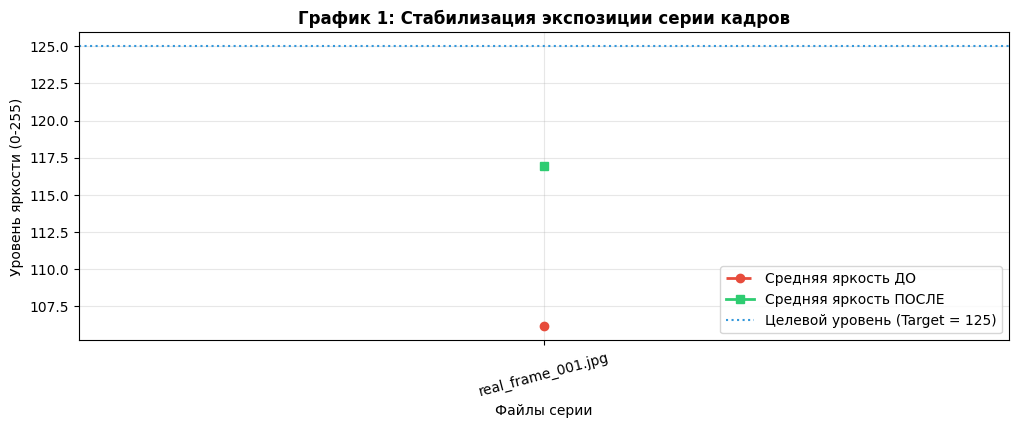

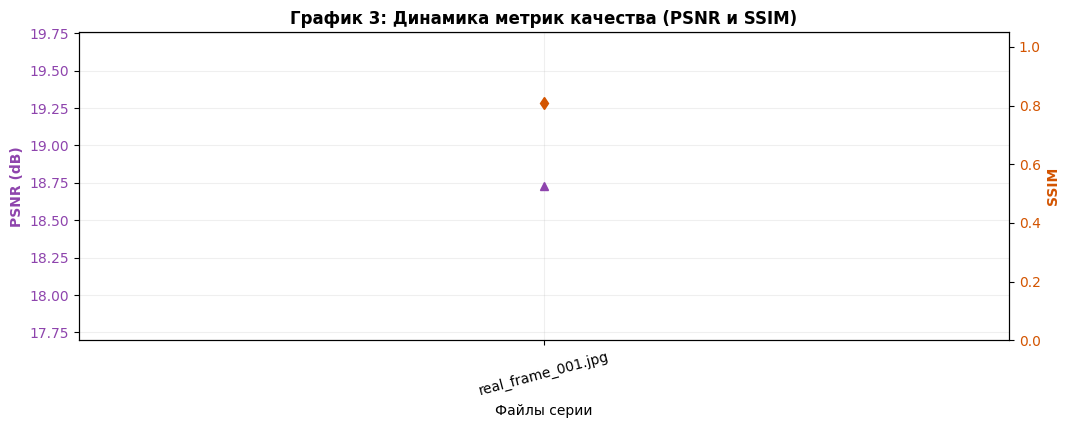

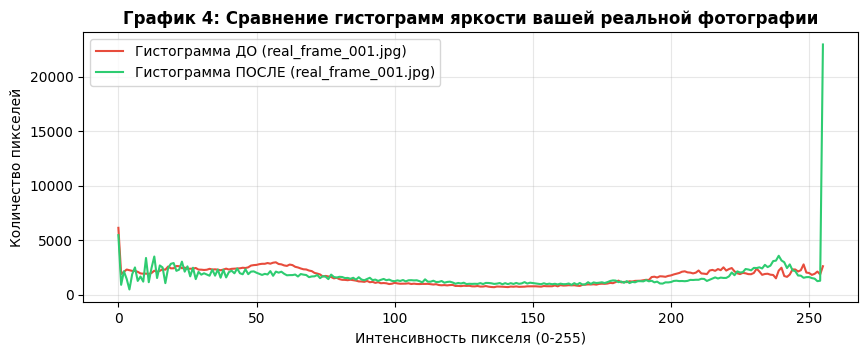

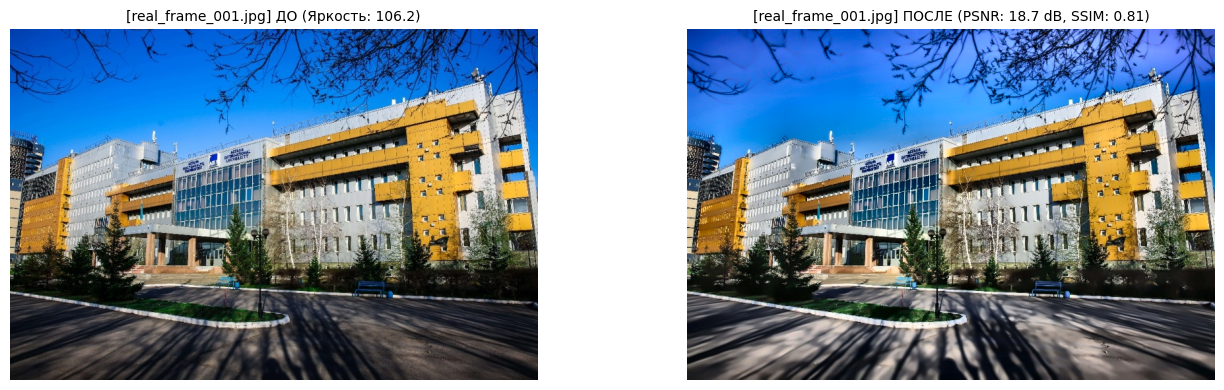

In [39]:
import numpy as np
import matplotlib.pyplot as plt

if len(execution_results) == 0:
    raise ValueError("Сначала запустите Блок 4, чтобы появились данные для графиков!")

f_names = [r["filename"] for r in execution_results]
orig_m = [r["orig_mean"] for r in execution_results]
proc_m = [r["proc_mean"] for r in execution_results]
psnr_vals = [r["psnr"] for r in execution_results]
ssim_vals = [r["ssim"] for r in execution_results]


# ГРАФИК 1: Стабилизация яркости

plt.figure(figsize=(12, 4))
plt.plot(f_names, orig_m, marker='o', color='#e74c3c', linewidth=2, linestyle='--', label='Средняя яркость ДО')
plt.plot(f_names, proc_m, marker='s', color='#2ecc71', linewidth=2, linestyle='-', label='Средняя яркость ПОСЛЕ')
plt.axhline(y=125, color='#3498db', linestyle=':', label='Целевой уровень (Target = 125)')
plt.title("График 1: Стабилизация экспозиции серии кадров", fontsize=12, fontweight='bold')
plt.xlabel("Файлы серии", fontsize=10)
plt.ylabel("Уровень яркости (0-255)", fontsize=10)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()


# ГРАФИК 2: Межкадровый фликер (если больше 1 файла)

if len(orig_m) > 1:
    flicker_orig = np.abs(np.diff(orig_m))
    flicker_proc = np.abs(np.diff(proc_m))
    diff_x_labels = f_names[1:]

    plt.figure(figsize=(12, 3.5))
    plt.bar(np.arange(len(flicker_orig)) - 0.2, flicker_orig, width=0.4, color='#e74c3c', alpha=0.8, label='Скачок ДО')
    plt.bar(np.arange(len(flicker_proc)) + 0.2, flicker_proc, width=0.4, color='#2ecc71', alpha=0.8, label='Скачок ПОСЛЕ')
    plt.xticks(ticks=np.arange(len(diff_x_labels)), labels=diff_x_labels, rotation=15)
    plt.title("График 2: Количественная оценка межкадрового мерцания", fontsize=12, fontweight='bold')
    plt.xlabel("Переходы между кадрами", fontsize=10)
    plt.ylabel("Абсолютная разница яркости", fontsize=10)
    plt.legend()
    plt.grid(True, alpha=0.3, axis='y')
    plt.show()


# ГРАФИК 3: Динамика PSNR и SSIM

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.set_xlabel('Файлы серии', fontsize=10)
ax1.set_ylabel('PSNR (dB)', color='#8e44ad', fontsize=10, fontweight='bold')
ax1.plot(f_names, psnr_vals, color='#8e44ad', marker='^', linewidth=2, label='PSNR')
ax1.tick_params(axis='y', labelcolor='#8e44ad')
ax1.grid(True, alpha=0.2)
plt.xticks(rotation=15)

ax2 = ax1.twinx()
ax2.set_ylabel('SSIM', color='#d35400', fontsize=10, fontweight='bold')
ax2.plot(f_names, ssim_vals, color='#d35400', marker='d', linewidth=2, linestyle='-.', label='SSIM')
ax2.tick_params(axis='y', labelcolor='#d35400')
ax2.set_ylim(0, 1.05)

plt.title("График 3: Динамика метрик качества (PSNR и SSIM)", fontsize=12, fontweight='bold')
plt.show()

# ГРАФИК 4: Гистограммы яркости для вашего реального фото (первого файла)

sample_orig, sample_proc, _ = pipeline.process_frame(input_files[0])
hist_orig = cv2.calcHist([sample_orig], [0], None, [256], [0, 256])
hist_proc = cv2.calcHist([sample_proc], [0], None, [256], [0, 256])

plt.figure(figsize=(10, 3.5))
plt.plot(hist_orig, color='#e74c3c', linewidth=1.5, label=f'Гистограмма ДО ({f_names[0]})')
plt.plot(hist_proc, color='#2ecc71', linewidth=1.5, label=f'Гистограмма ПОСЛЕ ({f_names[0]})')
plt.title("График 4: Сравнение гистограмм яркости вашей реальной фотографии", fontsize=12, fontweight='bold')
plt.xlabel("Интенсивность пикселя (0-255)", fontsize=10)
plt.ylabel("Количество пикселей", fontsize=10)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ВИЗУАЛИЗАЦИЯ: Сравнение «До / После»

plt.figure(figsize=(14, 4 * len(visual_cache)))
for idx, (fname, orig_img, proc_img) in enumerate(visual_cache):
    orig_rgb = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
    proc_rgb = cv2.cvtColor(proc_img, cv2.COLOR_BGR2RGB)

    plt.subplot(len(visual_cache), 2, 2 * idx + 1)
    plt.imshow(orig_rgb)
    plt.title(f"[{fname}] ДО (Яркость: {execution_results[idx]['orig_mean']:.1f})", fontsize=10)
    plt.axis('off')

    plt.subplot(len(visual_cache), 2, 2 * idx + 2)
    plt.imshow(proc_rgb)
    plt.title(f"[{fname}] ПОСЛЕ (PSNR: {execution_results[idx]['psnr']:.1f} dB, SSIM: {execution_results[idx]['ssim']:.2f})", fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

# Блок 6: Научные выводы по проекту (Для отчета и защиты)

In [40]:
# Расчет итоговой сводки по метрикам
avg_psnr = np.mean([r["psnr"] for r in execution_results])
avg_ssim = np.mean([r["ssim"] for r in execution_results])
max_psnr = np.max([r["psnr"] for r in execution_results])
min_psnr = np.min([r["psnr"] for r in execution_results])

print("=" * 70)
print("ИТОГОВАЯ АНАЛИТИЧЕСКАЯ СВОДКА ПРОЕКТА:")
print(f"• Среднее значение PSNR по всей серии: {avg_psnr:.2f} dB (Диапазон: [{min_psnr:.2f}, {max_psnr:.2f}])")
print(f"• Среднее значение SSIM по всей серии: {avg_ssim:.4f}")
print("=" * 70)

ИТОГОВАЯ АНАЛИТИЧЕСКАЯ СВОДКА ПРОЕКТА:
• Среднее значение PSNR по всей серии: 18.73 dB (Диапазон: [18.73, 18.73])
• Среднее значение SSIM по всей серии: 0.8099
